# Milestone 4, Section 1.4: Simulated drift and continual updates

This notebook runs the continual-learning experiment of Section 1. A stream of labelled users arrives in seven drift intervals, from clean data to the severe shift that broke the Milestone 2 model in Milestone 3 (all 12 raw features +3 sd), and then back to clean data. Four update strategies are compared, each with its own deployed model:

| Strategy | What happens when the trigger fires |
|---|---|
| `static` | Nothing: the Milestone 2 model (v1) stays deployed |
| `retrain_new` | Full retrain on the new interval only (Milestone 3 approach) |
| `retrain_replay` | **Selected:** full retrain on the new interval plus the replay buffer |
| `warm_replay` | Warm-start boosting from the deployed model on the new interval plus the replay buffer; old trees frozen |

The trigger and the promotion gate are the Milestone 3 rules: an update starts only when the deployed model's Qini is below the floor in two consecutive windows of the interval's gate rows, and a candidate replaces the deployed model only if the lower end of the 95% paired bootstrap interval of its Qini gain is above zero. Every metric uses the untouched Milestone 2 test split, under the interval's drift (current) and without drift (retention).

**Known bias.** The stream draws its users from the training split, which the starting model v1 was trained on. The trigger and the promotion gate therefore score v1 on users it has already seen, where its Qini looks better than it is. This makes the trigger fire later and the gate reject updates against v1 more often than it would on new users, so the results understate how quickly updates happen. All strategies start from the same v1, so the comparison between them is not affected, and every reported metric uses the untouched test split. The check at the end of this notebook repeats the experiment from **v1-sim**, the same configuration trained only on the 2.8 million training rows that the stream does not use.

The experiment is run with five seeds (42, 1, 2, 3, 4). The seed decides which training-split users fall into each interval, which rows the replay buffer keeps, and the bootstrap resamples; the test split, drift schedule and XGBoost settings stay the same.

- **Part 1** shows the main run (seed 42) in detail: tables, the four-panel figure, efficiency and saved model versions (Section 1.4 tables and Figure 1.1).
- **Part 2** summarizes all five seeds: mean ± sd of every metric, how often each strategy triggered and was promoted, update cost, and a paired bootstrap on the full test split comparing the selected strategy with the alternatives.

Run all cells (Runtime > Run all): about 30-60 minutes on a Colab CPU runtime. Set `SEEDS = (42,)` for the main run only (about 10 minutes). Results are written to `outputs/continual/`.

In [10]:
# SETUP: install the XGBoost version the saved model was written with, and make the pipeline importable.
# The package is looked for (1) next to this notebook, (2) in an uploaded Milestone_4_code.zip,
# (3) in a clone of the GitHub repository (pulled again if it already exists).
%pip install -q xgboost==3.4.1 psutil
import os, sys, glob, zipfile, subprocess
PKG = None
if os.path.isdir("uplift_pipeline"):
    PKG = "."
if PKG is None and glob.glob("Milestone_4_code*.zip"):
    zipfile.ZipFile(sorted(glob.glob("Milestone_4_code*.zip"))[-1]).extractall(".")
    PKG = "Milestone 4"
if PKG is None:
    if os.path.isdir("INSE-6450"):
        subprocess.run(["git", "-C", "INSE-6450", "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/saopa28/INSE-6450.git"], check=True)
    PKG = os.path.join("INSE-6450", "Milestone 4")
if not os.path.isdir(os.path.join(PKG, "uplift_pipeline")):
    raise FileNotFoundError(f"uplift_pipeline not found in {PKG!r}. Push the 'Milestone 4' folder to GitHub, "
                            "or upload Milestone_4_code.zip to the Colab file panel and run this cell again.")
sys.path.insert(0, os.path.abspath(PKG))
import xgboost; print("xgboost", xgboost.__version__, "| pipeline from", os.path.abspath(PKG))

xgboost 3.4.1 | pipeline from /content/INSE-6450/Milestone 4


In [11]:
import json
import numpy as np, pandas as pd
from IPython.display import display
from uplift_pipeline import load_data, split, load_v1, summary, CONTINUAL, OUT_DIR
from uplift_pipeline.continual import run_seeds, plot_results, plot_seeds, baseline_efficiency, STRATEGIES

FRAC = 1.0                     # share of rows to use; 1.0 reproduces the Milestone 2 split exactly
DATA = None                    # None = download the engineered data from the repository release
SEEDS = (42, 1, 2, 3, 4)       # the first seed is the main run shown in Part 1
OUT = OUT_DIR / "continual"
pd.set_option("display.width", 250)

df = load_data(frac=FRAC) if DATA is None else load_data(DATA, frac=FRAC)
sp = split(df); del df
print({k: f"{len(v[2]):,} rows" for k, v in sp.items()})
v1 = load_v1()                                  # Milestone 2 X-learner
Xte, tte, yte = sp["test"]
print("v1 test metrics:", {k: round(v, 6) for k, v in summary(yte, tte, v1.score(Xte)).items()})
print("v1 trees used for prediction:", v1.trees())
pd.DataFrame([{"hyperparameter": k, "value": v} for k, v in CONTINUAL.items()])

{'train': '9,785,714 rows', 'val': '2,096,939 rows', 'test': '2,096,939 rows'}
v1 test metrics: {'qini': 0.000376, 'auuc': 0.000438, 'uplift@10%': 0.007954}
v1 trees used for prediction: {'mu1': 244, 'mu0': 55, 'tau1': 84, 'tau0': 19}


,hyperparameter,value
0,rows_per_step,1000000
1,split,"(0.6, 0.15, 0.25)"
2,buffer_size,200000
3,new_trees,200
4,warm_lr,0.05
5,warm_early_stop,20
6,gate_boot,100
7,floor_boot,50


In [12]:
# Runs the simulation once per seed (each seed's results and models go to outputs/continual/seed_<n>/)
res_all, summ, upd_all, upd_summ, boots = run_seeds(v1, sp, seeds=SEEDS, out_dir=OUT)
MAIN = SEEDS[0]
res, upd = res_all[res_all.seed == MAIN].drop(columns="seed"), upd_all[upd_all.seed == MAIN].drop(columns="seed")


================ seed 42 (1/5) ================
rows per step 1,000,000 | trigger window 125,000 rows | Qini floor 0.000156 (mean 0.000401, sd 0.000123)

Step 0: Clean
  static          v1                     PSI   0.000 | trigger False | Qini current +0.000376 -> +0.000376 | original +0.000376
  retrain_new     v1                     PSI   0.000 | trigger False | Qini current +0.000376 -> +0.000376 | original +0.000376
  retrain_replay  v1                     PSI   0.000 | trigger False | Qini current +0.000376 -> +0.000376 | original +0.000376
  warm_replay     v1                     PSI   0.000 | trigger False | Qini current +0.000376 -> +0.000376 | original +0.000376

Step 1: f9 +0.5 sd
  static          v1                     PSI  13.284 | trigger False | Qini current +0.000376 -> +0.000376 | original +0.000376
  retrain_new     v1                     PSI  13.284 | trigger False | Qini current +0.000376 -> +0.000376 | original +0.000376
  retrain_replay  v1                     PS

# Part 1: main run (seed 42)
## Metrics before and after each update
`qini_before` is the deployed model when the interval arrives; `qini_after` is the model deployed after the interval's update decision. Both are on the test split under the interval's drift. `qini_original` is the deployed model on the test split without drift (retention of old knowledge).

In [13]:
cols = ["step", "drift", "strategy", "psi_max", "monitor", "triggered", "updated", "promoted", "version_after",
        "qini_before", "qini_after", "auuc_before", "auuc_after", "uplift10_before", "uplift10_after", "qini_original", "auuc_original", "gate_ci_lo", "gate_ci_hi"]
display(res.reindex(columns=cols).round(6))

,step,drift,strategy,psi_max,monitor,triggered,updated,promoted,version_after,qini_before,qini_after,auuc_before,auuc_after,uplift10_before,uplift10_after,qini_original,auuc_original,gate_ci_lo,gate_ci_hi
0,0,Clean,static,0.000039,OK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.007954,0.007954,0.000376,0.000438,NaN,NaN
1,0,Clean,retrain_new,0.000039,OK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.007954,0.007954,0.000376,0.000438,NaN,NaN
2,0,Clean,retrain_replay,0.000039,OK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.007954,0.007954,0.000376,0.000438,NaN,NaN
3,0,Clean,warm_replay,0.000039,OK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.007954,0.007954,0.000376,0.000438,NaN,NaN
4,1,f9 +0.5 sd,static,13.284343,BLOCK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.008040,0.008040,0.000376,0.000438,NaN,NaN
5,1,f9 +0.5 sd,retrain_new,13.284343,BLOCK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.008040,0.008040,0.000376,0.000438,NaN,NaN
6,1,f9 +0.5 sd,retrain_replay,13.284343,BLOCK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.008040,0.008040,0.000376,0.000438,NaN,NaN
7,1,f9 +0.5 sd,warm_replay,13.284343,BLOCK,False,False,False,v1,0.000376,0.000376,0.000438,0.000438,0.008040,0.008040,0.000376,0.000438,NaN,NaN
8,2,All raw +1 sd,static,13.305545,BLOCK,False,False,False,v1,0.000377,0.000377,0.000439,0.000439,0.008078,0.008078,0.000376,0.000438,NaN,NaN
9,2,All raw +1 sd,retrain_new,13.305545,BLOCK,False,False,False,v1,0.000377,0.000377,0.000439,0.000439,0.008078,0.008078,0.000376,0.000438,NaN,NaN


In [14]:
cur = res.pivot(index=["step", "drift"], columns="strategy", values="qini_after")[list(STRATEGIES)]
ret = res.pivot(index=["step", "drift"], columns="strategy", values="qini_original")[list(STRATEGIES)]
print("Qini under the current drift"); display(cur.round(6))
print("Qini on the original (undrifted) test data"); display(ret.round(6))

Qini under the current drift


,strategy,static,retrain_new,retrain_replay,warm_replay
step,drift,,,,
0,Clean,0.000376,0.000376,0.000376,0.000376
1,f9 +0.5 sd,0.000376,0.000376,0.000376,0.000376
2,All raw +1 sd,0.000377,0.000377,0.000377,0.000377
3,All raw +2 sd,0.000134,0.000134,0.000337,0.000269
4,All raw +3 sd,-0.000097,0.000323,0.000307,0.000208
5,All raw +3 sd (stable),-0.000097,0.000323,0.000307,0.000208
6,Clean (recurrence),0.000376,0.000205,0.000363,0.000354


Qini on the original (undrifted) test data


,strategy,static,retrain_new,retrain_replay,warm_replay
step,drift,,,,
0,Clean,0.000376,0.000376,0.000376,0.000376
1,f9 +0.5 sd,0.000376,0.000376,0.000376,0.000376
2,All raw +1 sd,0.000376,0.000376,0.000376,0.000376
3,All raw +2 sd,0.000376,0.000376,0.000363,0.000354
4,All raw +3 sd,0.000376,0.000205,0.000363,0.000354
5,All raw +3 sd (stable),0.000376,0.000205,0.000363,0.000354
6,Clean (recurrence),0.000376,0.000205,0.000363,0.000354


## Efficiency of each promoted update
Update time, peak process memory (RSS) during the update, model size (stage-2 boosters used for scoring), number of trees, and model-only scoring latency for one request (batch 1) and a 256-row batch. Colab CPU runtime, so there is no VRAM figure.

In [15]:
eff = pd.concat([pd.DataFrame([baseline_efficiency(v1, Xte)]), upd], ignore_index=True)
eff.to_csv(OUT / f"seed_{MAIN}" / "efficiency.csv", index=False)
display(eff.round(3))

,version,trees_scoring,trees_total,scoring_size_mb,p50_ms_b1,p90_ms_b1,p50_ms_b256,p90_ms_b256,throughput_rows_s,step,strategy,parent,update_s,peak_rss_mb
0,v1,103,402,0.158,0.530,0.599,1.035,1.150,247316.710,NaN,NaN,NaN,NaN,NaN
1,retrain_replay-step3,56,130,0.081,0.465,0.510,0.791,0.857,323679.630,3.0,retrain_replay,v1,12.115,2020.348
2,warm_replay-step3,302,756,0.433,0.594,2.627,1.697,2.760,150860.583,3.0,warm_replay,v1,26.572,1999.081
3,retrain_new-step4,71,140,0.095,0.481,0.539,0.900,0.999,284442.548,4.0,retrain_new,v1,10.015,1938.047


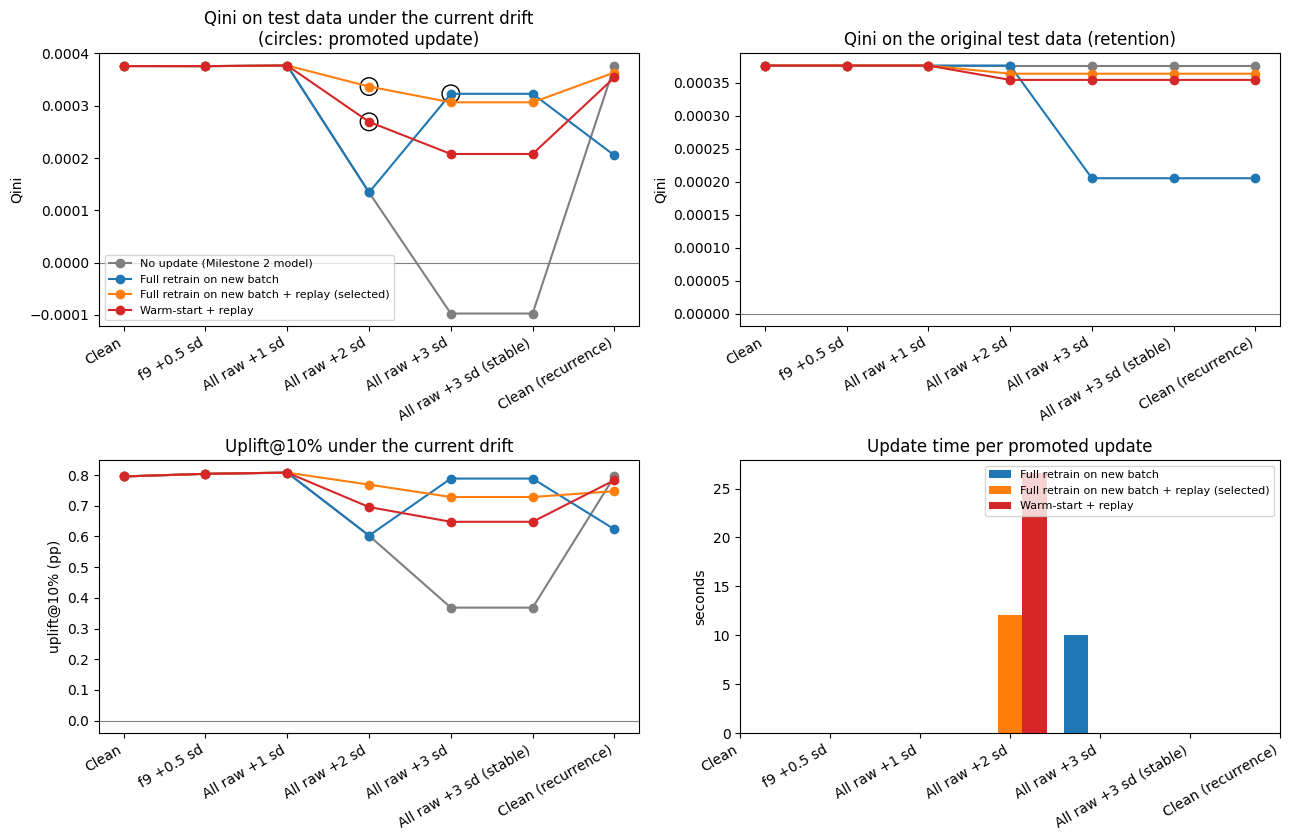

In [16]:
fig = plot_results(res, upd, OUT / f"seed_{MAIN}")       # Figure 1.1

In [17]:
# Saved model versions of the main run (each has a manifest with its parent, training rows, gate result and file hashes)
for d in sorted((OUT / f"seed_{MAIN}" / "models").iterdir()):
    m = json.loads((d / "manifest.json").read_text())
    print(f"{m['version']:24s} parent={m['parent']:22s} trees={m['trees']} size={m['scoring_size_mb']} MB")

retrain_new-step4        parent=v1                     trees={'mu1': 41, 'mu0': 28, 'tau1': 40, 'tau0': 31} size=0.0953 MB
retrain_replay-step3     parent=v1                     trees={'mu1': 52, 'mu0': 22, 'tau1': 22, 'tau0': 34} size=0.0807 MB
warm_replay-step3        parent=v1                     trees={'mu1': 355, 'mu0': 99, 'tau1': 226, 'tau0': 76} size=0.4333 MB


# Part 2: all seeds
## Mean ± sd across seeds

In [18]:
def table(metric):
    m = summ.pivot(index=["step", "drift"], columns="strategy", values=f"{metric}_mean")[list(STRATEGIES)]
    s = summ.pivot(index=["step", "drift"], columns="strategy", values=f"{metric}_sd")[list(STRATEGIES)]
    return m.map(lambda v: f"{v:.6f}") + " ± " + s.fillna(0).map(lambda v: f"{v:.6f}")
print("Qini under the current drift"); display(table("qini_after"))
print("Qini on the original test data (retention)"); display(table("qini_original"))
print("Uplift@10% under the current drift"); display(table("uplift10_after"))
print(f"Seeds (out of {len(SEEDS)}) that triggered / promoted an update")
display(summ.pivot(index=["step", "drift"], columns="strategy", values="seeds_triggered")[list(STRATEGIES)].astype(int).astype(str)
        + " / " + summ.pivot(index=["step", "drift"], columns="strategy", values="seeds_promoted")[list(STRATEGIES)].astype(int).astype(str))

Qini under the current drift


,strategy,static,retrain_new,retrain_replay,warm_replay
step,drift,,,,
0,Clean,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000
1,f9 +0.5 sd,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000
2,All raw +1 sd,0.000377 ± 0.000000,0.000377 ± 0.000000,0.000377 ± 0.000000,0.000377 ± 0.000000
3,All raw +2 sd,0.000134 ± 0.000000,0.000134 ± 0.000000,0.000217 ± 0.000114,0.000180 ± 0.000064
4,All raw +3 sd,-0.000097 ± 0.000000,0.000081 ± 0.000244,0.000069 ± 0.000228,0.000112 ± 0.000193
5,All raw +3 sd (stable),-0.000097 ± 0.000000,0.000326 ± 0.000051,0.000335 ± 0.000026,0.000258 ± 0.000043
6,Clean (recurrence),0.000376 ± 0.000000,0.000278 ± 0.000063,0.000334 ± 0.000033,0.000312 ± 0.000042


Qini on the original test data (retention)


,strategy,static,retrain_new,retrain_replay,warm_replay
step,drift,,,,
0,Clean,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000
1,f9 +0.5 sd,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000
2,All raw +1 sd,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000376 ± 0.000000
3,All raw +2 sd,0.000376 ± 0.000000,0.000376 ± 0.000000,0.000367 ± 0.000015,0.000373 ± 0.000011
4,All raw +3 sd,0.000376 ± 0.000000,0.000339 ± 0.000075,0.000367 ± 0.000015,0.000330 ± 0.000056
5,All raw +3 sd (stable),0.000376 ± 0.000000,0.000278 ± 0.000063,0.000334 ± 0.000033,0.000312 ± 0.000042
6,Clean (recurrence),0.000376 ± 0.000000,0.000278 ± 0.000063,0.000334 ± 0.000033,0.000312 ± 0.000042


Uplift@10% under the current drift


,strategy,static,retrain_new,retrain_replay,warm_replay
step,drift,,,,
0,Clean,0.007954 ± 0.000000,0.007954 ± 0.000000,0.007954 ± 0.000000,0.007954 ± 0.000000
1,f9 +0.5 sd,0.008040 ± 0.000000,0.008040 ± 0.000000,0.008040 ± 0.000000,0.008040 ± 0.000000
2,All raw +1 sd,0.008078 ± 0.000000,0.008078 ± 0.000000,0.008078 ± 0.000000,0.008078 ± 0.000000
3,All raw +2 sd,0.006027 ± 0.000000,0.006027 ± 0.000000,0.006688 ± 0.000906,0.006361 ± 0.000462
4,All raw +3 sd,0.003680 ± 0.000000,0.005472 ± 0.002461,0.005237 ± 0.002141,0.005630 ± 0.001804
5,All raw +3 sd (stable),0.003680 ± 0.000000,0.007747 ± 0.000714,0.007679 ± 0.000320,0.006842 ± 0.000592
6,Clean (recurrence),0.007954 ± 0.000000,0.006547 ± 0.000723,0.007405 ± 0.000320,0.007465 ± 0.000430


Seeds (out of 5) that triggered / promoted an update


,strategy,static,retrain_new,retrain_replay,warm_replay
step,drift,,,,
0,Clean,0 / 0,0 / 0,0 / 0,0 / 0
1,f9 +0.5 sd,0 / 0,0 / 0,0 / 0,0 / 0
2,All raw +1 sd,0 / 0,0 / 0,0 / 0,0 / 0
3,All raw +2 sd,3 / 0,3 / 0,3 / 2,3 / 2
4,All raw +3 sd,4 / 0,4 / 2,2 / 0,3 / 2
5,All raw +3 sd (stable),5 / 0,3 / 3,4 / 3,3 / 2
6,Clean (recurrence),0 / 0,1 / 0,0 / 0,0 / 0


## Update cost across seeds

In [19]:
display(upd_summ.round(3))

,strategy,updates,update_s_mean,update_s_sd,peak_rss_mb_mean,trees_scoring_mean,size_mb_mean,p50_ms_b1_mean,p50_ms_b256_mean
0,retrain_new,5,10.376,0.361,1964.219,61.400,0.084,0.501,0.863
1,retrain_replay,5,14.103,1.479,2045.958,64.400,0.091,0.486,1.005
2,warm_replay,6,27.608,3.572,2055.531,289.667,0.414,0.690,2.963


## Paired bootstrap on the test split: selected strategy minus the alternative
A positive gain means retrain + replay ranks better. The interval is the 95% paired bootstrap interval on the full test split (200 resamples); a gain of 0 with an empty interval means both strategies had the same model deployed.

In [20]:
display(boots.round(6))
print("\nSeeds where the selected strategy is significantly better (CI above 0) / worse (CI below 0):")
display(boots.groupby(["step", "drift", "other"]).apply(
    lambda g: pd.Series({"better": int((g.ci_lo > 0).sum()), "worse": int((g.ci_hi < 0).sum()),
                         "mean_gain": g.qini_gain.mean()}), include_groups=False))

,seed,step,drift,selected,other,other_version,qini_gain,ci_lo,ci_hi,p_selected_better
0,42,3,All raw +2 sd,retrain_replay-step3,warm_replay,warm_replay-step3,0.000068,0.000005,0.000121,0.975
1,42,3,All raw +2 sd,retrain_replay-step3,retrain_new,v1,0.000202,0.000111,0.000286,1.000
2,42,5,All raw +3 sd (stable),retrain_replay-step3,warm_replay,warm_replay-step3,0.000099,0.000030,0.000163,1.000
3,42,5,All raw +3 sd (stable),retrain_replay-step3,retrain_new,retrain_new-step4,-0.000016,-0.000086,0.000056,0.370
4,42,6,Clean (recurrence),retrain_replay-step3,warm_replay,warm_replay-step3,0.000009,-0.000028,0.000049,0.695
5,42,6,Clean (recurrence),retrain_replay-step3,retrain_new,retrain_new-step4,0.000158,0.000101,0.000225,1.000
6,1,3,All raw +2 sd,v1,warm_replay,v1,0.000000,0.000000,0.000000,NaN
7,1,3,All raw +2 sd,v1,retrain_new,v1,0.000000,0.000000,0.000000,NaN
8,1,5,All raw +3 sd (stable),retrain_replay-step5,warm_replay,warm_replay-step5,0.000069,0.000018,0.000127,0.980
9,1,5,All raw +3 sd (stable),retrain_replay-step5,retrain_new,retrain_new-step5,0.000012,-0.000032,0.000057,0.715



Seeds where the selected strategy is significantly better (CI above 0) / worse (CI below 0):


better  worse  mean_gain
step drift                  other                                
3    All raw +2 sd          retrain_new     2.0    0.0   0.000083
                            warm_replay     2.0    0.0   0.000037
5    All raw +3 sd (stable) retrain_new     1.0    0.0   0.000009
                            warm_replay     4.0    0.0   0.000078
6    Clean (recurrence)     retrain_new     3.0    0.0   0.000056
                            warm_replay     1.0    1.0   0.000021

Files written: ['continual_config.json', 'continual_steps.csv', 'continual_trajectories.png', 'continual_updates.csv', 'efficiency.csv', 'models', 'seed_1', 'seed_2', 'seed_3', 'seed_4', 'seed_42', 'seeds_bootstrap.csv', 'seeds_steps.csv', 'seeds_summary.csv', 'seeds_trajectories.png', 'seeds_update_summary.csv', 'seeds_updates.csv']


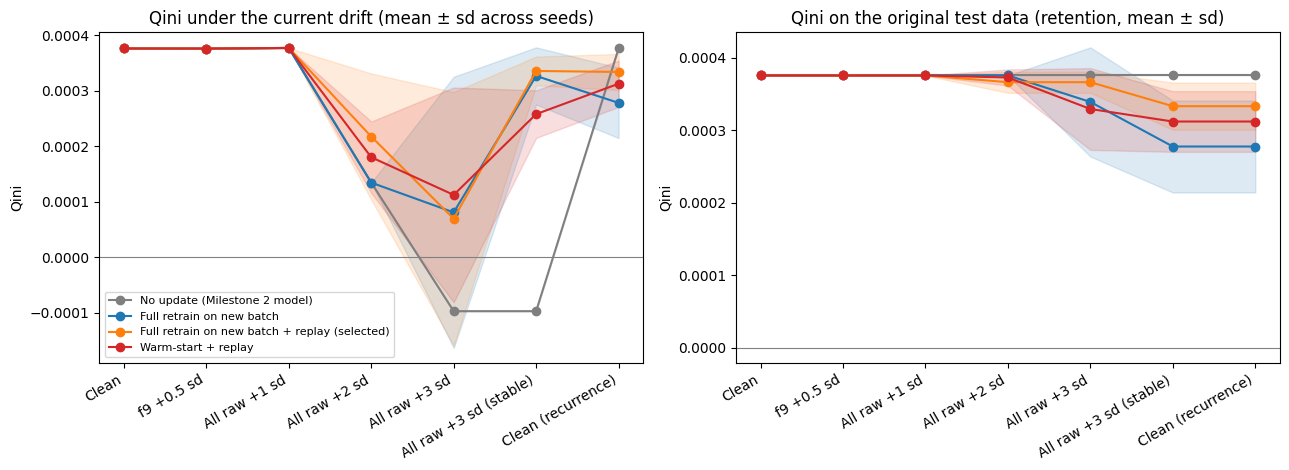

In [21]:
fig = plot_seeds(summ, OUT)
print("Files written:", sorted(p.name for p in OUT.iterdir()))

# Check: starting from a model that never saw the stream (v1-sim)
v1-sim is the Milestone 2 configuration trained on the 2.8 million training rows the stream does not use, so the trigger and the gate only score it on unseen users. In our run (5 seeds) it was much more robust to the drift than v1: test Qini 0.000368 clean, 0.000365 at +2 sd and 0.000256 at +3 sd (v1: 0.000376, 0.000134 and −0.000097). It never fell below the trigger floor, so no strategy updated in any seed. The collapse under mean shifts is therefore specific to the v1 model rather than to this model class, and a starting model that does not degrade cannot test the update strategies, which is why the main experiment starts from v1. Set `RUN_V1SIM_CHECK = True` to reproduce it (about 5-10 minutes).

In [ ]:
RUN_V1SIM_CHECK = False
if RUN_V1SIM_CHECK:
    from uplift_pipeline.continual import fit_base
    CHECK = OUT / "v1sim_check"
    base, stream_idx, base_idx = fit_base(v1, sp, out_dir=CHECK)
    _, summ_sim, _, _, _ = run_seeds(base, sp, seeds=SEEDS, out_dir=CHECK, stream_idx=stream_idx,
                                     base_idx=base_idx, base_version="v1-sim")
    print("v1-sim: Qini under the current drift (mean across seeds)")
    display(summ_sim.pivot(index=["step", "drift"], columns="strategy", values="qini_after_mean")[list(STRATEGIES)].round(6))
    print("Seeds that triggered an update:")
    display(summ_sim.pivot(index=["step", "drift"], columns="strategy", values="seeds_triggered")[list(STRATEGIES)])